In [1]:
import matplotlib.pyplot as plt
import pandas as pd

In [18]:
num_agent = 5
random_seed = 0

num_trained_model = 5
train_seed = 0

In [19]:
folder = f"NUM_AGENT{str(num_agent).zfill(2)}/{str(train_seed).zfill(4)}/"

reward_csv = folder + f"reward_output/reward_history-NUM_AGENT{str(num_agent).zfill(2)}-Random_seed{str(train_seed).zfill(4)}.csv"
distance_csv = folder + f"distance_output/total_distance_list-NUM_AGENT{str(num_agent).zfill(2)}-Random_seed{str(train_seed).zfill(4)}.csv"
trajectory_csv = folder + f"greedy_output/check_position_heading-NUM_AGENT{str(num_agent).zfill(2)}-Random_seed{str(random_seed).zfill(4)}-NUMBER_OF_AGENT_TRAINED_MODEL{str(num_trained_model).zfill(2)}-Random_seed_trained_model{str(train_seed).zfill(4)}.csv"


<AxesSubplot:>

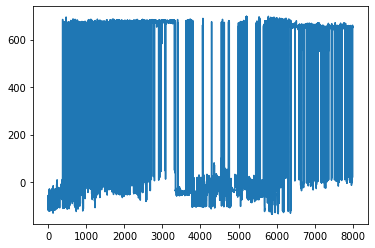

In [20]:
df_reward = pd.read_csv(reward_csv, header=None)
df_reward.loc[0, :].plot()

success rate: 0.98
up rate: 0.6428571428571429
low rate: 0.35714285714285715


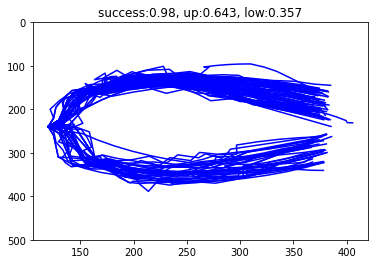

In [49]:
# plot the trajectories of the box with all random seeds
figure = plt.figure()

count_success = 0
count_up = 0
count_low = 0
total_num = 100

for train_seed in range(total_num):
    folder = f"NUM_AGENT{str(num_agent).zfill(2)}/{str(train_seed).zfill(4)}/"
    trajectory_csv = folder + f"greedy_output/check_position_heading-NUM_AGENT{str(num_agent).zfill(2)}-Random_seed{str(random_seed).zfill(4)}-NUMBER_OF_AGENT_TRAINED_MODEL{str(num_trained_model).zfill(2)}-Random_seed_trained_model{str(train_seed).zfill(4)}.csv"
    success_csv = folder + f"greedy_output/check_success-NUM_AGENT{str(num_agent).zfill(2)}-Random_seed{str(random_seed).zfill(4)}-NUMBER_OF_AGENT_TRAINED_MODEL{str(num_trained_model).zfill(2)}-Random_seed_trained_model{str(train_seed).zfill(4)}.csv"
    
    # check success rate
    df_success = pd.read_csv(success_csv, header=None)
    if df_success.loc[0, 0] < 1:
        continue
    count_success += 1
    
    df_trajectory = pd.read_csv(trajectory_csv, header=None)
    x = df_trajectory.loc[:, 1].to_numpy()
    y = df_trajectory.loc[:, 2].to_numpy()
    plt.plot(x, y, "b")
    
    if min(y) > 200:
        count_low += 1
    else:
        count_up += 1
        
print(f"success rate: {count_success/total_num}")
print(f"up rate: {count_up/count_success}")
print(f"low rate: {count_low/count_success}")

plt.title(f"success:{count_success/total_num}, up:{count_up/count_success :.3f}, low:{count_low/count_success :.3f}")
plt.ylim([500, 0])
import os
if not os.path.exists("plots"):
    os.makedirs("plots")
plt.savefig(f"plots/NUM_AGENT{str(num_agent).zfill(2)}-Random_seed{str(random_seed).zfill(4)}-NUMBER_OF_AGENT_TRAINED_MODEL{str(num_trained_model).zfill(2)}.png",
           facecolor="white")